# Week 4: Compare, Cross-Validate and Tune Models
**Dataset:** `healthcare_data.csv` (17,498 patients, 14 columns)
**Target (category):** `status` → Admitted / Discharged / Under Treatment (3 balanced classes)

## Step 0: Load the data (Google Colab)

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')

# Upload healthcare_data.csv when asked (skips upload if the file is already in Colab)
import os
if not os.path.exists('healthcare_data.csv'):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

df = pd.read_csv('healthcare_data.csv')
print(df.shape)
df.head()

Saving healthcare_data.csv to healthcare_data.csv
(17498, 14)


,patient_id,first_name,last_name,age,gender,phone,email,department,diagnosis,treatment,admission_date,discharge_date,status,bill_amount
0,PID1000,Victor,Hoffman,60,Male,578-267-5326x77210,turnermichelle@example.org,Pediatrics,Migraine,Medication,2024-02-10,2025-06-01,Admitted,100900.97
1,PID1001,John,Sparks,11,Other,(263)977-2102x55652,amandagarner@example.net,Dermatology,Diabetes,Medication,2023-11-18,2025-01-26,Discharged,120905.91
2,PID1002,Isabella,Rubio,2,Female,275.597.9494,james75@example.org,Neurology,Asthma,Medication,2023-12-04,2025-03-02,Under Treatment,170672.18
3,PID1003,Allison,Hill,22,Other,4857130035,salazaralice@example.net,Cardiology,Cancer,Observation,2023-12-25,2024-10-07,Discharged,149977.74
4,PID1004,James,Berry,8,Female,791-362-4064,christinaalexander@example.net,Neurology,Cancer,Observation,2025-02-14,2024-11-15,Under Treatment,160039.43


## Step 1: Prepare the data
- Drop identifier / contact columns (`patient_id`, names, phone, email): they are unique per row and carry no medical signal.
- Convert dates, create `length_of_stay` and admission month/year.
- Fix impossible values (discharge before admission → missing) and fill missing values with the median.
- One-hot encode text columns, label-encode the target.
- 80/20 split with `stratify=y`, `random_state=42`. **The test set is not used again until Step 5/6.**

In [2]:
print('Missing values:\n', df.isna().sum()[df.isna().sum() > 0])
print('Duplicate rows:', df.duplicated().sum())
print('\nTarget distribution:\n', df['status'].value_counts())

Missing values:
 Series([], dtype: int64)
Duplicate rows: 0

Target distribution:
 status
Admitted           5883
Under Treatment    5860
Discharged         5755
Name: count, dtype: int64


In [3]:
data = df.copy()
data = data.drop_duplicates()

# Dates -> numeric features
data['admission_date'] = pd.to_datetime(data['admission_date'], errors='coerce')
data['discharge_date'] = pd.to_datetime(data['discharge_date'], errors='coerce')
data['length_of_stay'] = (data['discharge_date'] - data['admission_date']).dt.days
data['admit_month'] = data['admission_date'].dt.month
data['admit_year']  = data['admission_date'].dt.year

# Invalid: discharge before admission -> treat as missing
bad = (data['length_of_stay'] < 0).sum()
print(f'Rows with discharge before admission: {bad} ({bad/len(data):.1%}) -> set to NaN')
data.loc[data['length_of_stay'] < 0, 'length_of_stay'] = np.nan

# Drop columns that identify a person (no predictive meaning) and raw dates
data = data.drop(columns=['patient_id','first_name','last_name','phone','email',
                          'admission_date','discharge_date'])

# Missing values: numeric -> median
for c in data.select_dtypes('number').columns:
    data[c] = data[c].fillna(data[c].median())

# Target + features
y_raw = data['status']
X = data.drop(columns='status')

# Encode text columns (one-hot)
X = pd.get_dummies(X, columns=['gender','department','diagnosis','treatment'], drop_first=True)

# Encode target
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = pd.Series(le.fit_transform(y_raw), name='status')
print('Classes:', dict(zip(le.classes_, le.transform(le.classes_))))
print('X shape:', X.shape)
X.head()

Rows with discharge before admission: 4382 (25.0%) -> set to NaN
Classes: {'Admitted': np.int64(0), 'Discharged': np.int64(1), 'Under Treatment': np.int64(2)}
X shape: (17498, 24)


,age,bill_amount,length_of_stay,admit_month,admit_year,gender_Male,gender_Other,department_Dermatology,department_General Medicine,department_Neurology,...,diagnosis_Diabetes,diagnosis_Flu,diagnosis_Fracture,diagnosis_Healthy,diagnosis_Hypertension,diagnosis_Migraine,treatment_Observation,treatment_Surgery,treatment_Therapy,treatment_Vaccination
0,60,100900.97,477.0,2,2024,True,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,11,120905.91,435.0,11,2023,False,True,True,False,False,...,True,False,False,False,False,False,False,False,False,False
2,2,170672.18,454.0,12,2023,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
3,22,149977.74,287.0,12,2023,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,8,160039.43,273.0,2,2025,False,False,False,False,True,...,False,False,False,False,False,False,True,False,False,False


In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train class share:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Test  class share:', y_test.value_counts(normalize=True).round(3).to_dict())

Train: (13998, 24)  Test: (3500, 24)
Train class share: {0: 0.336, 2: 0.335, 1: 0.329}
Test  class share: {0: 0.336, 2: 0.335, 1: 0.329}


## Step 2: Compare four models with 5-fold cross-validation (training data only)
KNN uses `make_pipeline(StandardScaler(), KNN)` so scaling is fitted inside each fold (no leakage).

In [5]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'KNN':               make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'Decision Tree':     DecisionTreeClassifier(random_state=42),
    'Random Forest':     RandomForestClassifier(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    rows.append({'Model': name, 'Mean CV accuracy': s.mean(), 'Std': s.std()})
    print(f'{name:18s} mean = {s.mean():.4f}   std = {s.std():.4f}')

cv_table = pd.DataFrame(rows).sort_values('Mean CV accuracy', ascending=False).reset_index(drop=True)
cv_table.round(4)

KNN                mean = 0.3337   std = 0.0064
Decision Tree      mean = 0.3283   std = 0.0074
Random Forest      mean = 0.3275   std = 0.0066
Gradient Boosting  mean = 0.3348   std = 0.0028


,Model,Mean CV accuracy,Std
0,Gradient Boosting,0.3348,0.0028
1,KNN,0.3337,0.0064
2,Decision Tree,0.3283,0.0074
3,Random Forest,0.3275,0.0066


## Step 3: Tune two simple models and plot the results

 K  CV mean  CV std
 1   0.3368  0.0045
 3   0.3339  0.0073
 5   0.3337  0.0064
 7   0.3329  0.0064
 9   0.3331  0.0055
11   0.3362  0.0063
13   0.3280  0.0083
15   0.3300  0.0053

Best K = 1


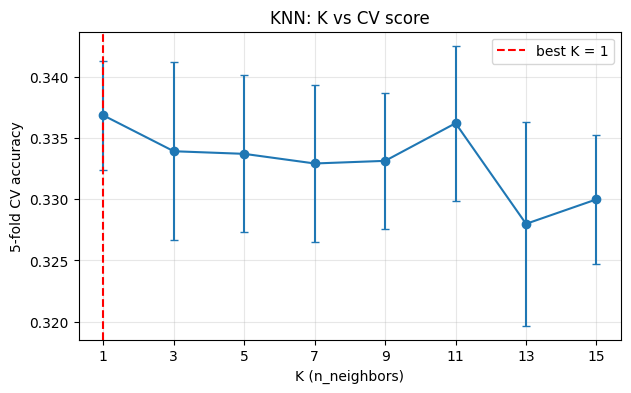

In [6]:
# --- KNN: K = 1, 3, 5, ..., 15 ---
k_values = list(range(1, 16, 2))
knn_mean, knn_std = [], []
for k in k_values:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    s = cross_val_score(pipe, X_train, y_train, cv=cv, n_jobs=-1)
    knn_mean.append(s.mean()); knn_std.append(s.std())

knn_res = pd.DataFrame({'K': k_values, 'CV mean': knn_mean, 'CV std': knn_std})
print(knn_res.round(4).to_string(index=False))
best_k = k_values[int(np.argmax(knn_mean))]
print('\nBest K =', best_k)

plt.figure(figsize=(7,4))
plt.errorbar(k_values, knn_mean, yerr=knn_std, marker='o', capsize=3)
plt.axvline(best_k, color='red', ls='--', label=f'best K = {best_k}')
plt.xlabel('K (n_neighbors)'); plt.ylabel('5-fold CV accuracy'); plt.title('KNN: K vs CV score')
plt.xticks(k_values); plt.legend(); plt.grid(alpha=.3); plt.show()

max_depth  CV mean  CV std
        2   0.3400  0.0039
        3   0.3394  0.0069
        5   0.3355  0.0075
       10   0.3370  0.0086
     None   0.3283  0.0074

Best max_depth = 2


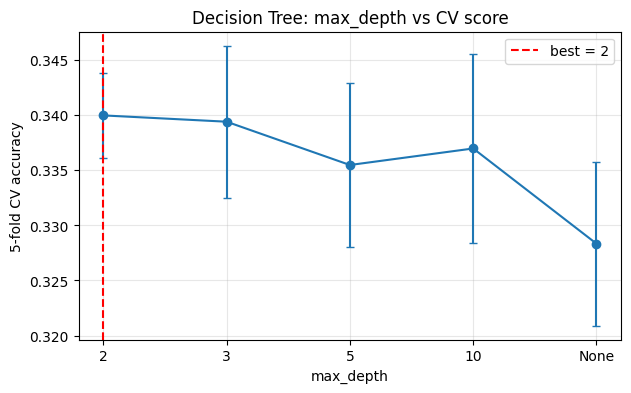

In [7]:
# --- Decision Tree: max_depth = 2, 3, 5, 10, None ---
depths = [2, 3, 5, 10, None]
dt_mean, dt_std = [], []
for d in depths:
    s = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42),
                        X_train, y_train, cv=cv, n_jobs=-1)
    dt_mean.append(s.mean()); dt_std.append(s.std())

dt_res = pd.DataFrame({'max_depth': [str(d) for d in depths], 'CV mean': dt_mean, 'CV std': dt_std})
print(dt_res.round(4).to_string(index=False))
best_depth = depths[int(np.argmax(dt_mean))]
print('\nBest max_depth =', best_depth)

labels = [str(d) for d in depths]
plt.figure(figsize=(7,4))
plt.errorbar(range(len(depths)), dt_mean, yerr=dt_std, marker='o', capsize=3)
plt.axvline(int(np.argmax(dt_mean)), color='red', ls='--', label=f'best = {best_depth}')
plt.xticks(range(len(depths)), labels)
plt.xlabel('max_depth'); plt.ylabel('5-fold CV accuracy'); plt.title('Decision Tree: max_depth vs CV score')
plt.legend(); plt.grid(alpha=.3); plt.show()

### Which values I chose and why
- **KNN → K = 1** (highest CV mean, 0.3368). But the gap to K = 11 (0.3362) is far smaller than the std (≈0.005–0.006), so the K values are practically equal. K = 1 simply memorises each patient (train score 1.00 in Step 5), so in a real project I would prefer a larger, more stable K such as 11. I use odd K only to avoid ties between the 3 classes.
- **Decision Tree → max_depth = 2** (highest CV mean, 0.3400). Deeper trees do worse: `None` (fully grown) is the lowest (0.3283) because it memorises noise in the training data. The shallow tree is also the simplest and most stable.
- On this dataset every score is ≈ 0.33 (random guessing for 3 balanced classes), so the differences between values are small. See the final discussion.

## Step 4: Tune the Random Forest with GridSearchCV
Grid: `n_estimators = [50, 100, 200]`, `max_depth = [3, 5, None]`, `cv=5`.

In [8]:
from sklearn.model_selection import GridSearchCV

rf_grid = {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, None]}
rf_gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                     rf_grid, cv=5, scoring='accuracy', n_jobs=-1)
rf_gs.fit(X_train, y_train)

print('best_params_:', rf_gs.best_params_)
print('best_score_ :', round(rf_gs.best_score_, 4))

n_comb = len(rf_grid['n_estimators']) * len(rf_grid['max_depth'])
print(f'\nTrainings: {n_comb} combinations x 5 folds = {n_comb*5} trainings (+1 final refit on all training data)')

pd.DataFrame(rf_gs.cv_results_)[['param_n_estimators','param_max_depth','mean_test_score','std_test_score']].round(4)

best_params_: {'max_depth': 5, 'n_estimators': 100}
best_score_ : 0.3427

Trainings: 9 combinations x 5 folds = 45 trainings (+1 final refit on all training data)


,param_n_estimators,param_max_depth,mean_test_score,std_test_score
0,50,3,0.3423,0.0056
1,100,3,0.3380,0.0068
2,200,3,0.3415,0.0065
3,50,5,0.3400,0.0033
4,100,5,0.3427,0.0031
5,200,5,0.3403,0.0039
6,50,None,0.3374,0.0037
7,100,None,0.3333,0.0036
8,200,None,0.3334,0.0070


## Bonus: Tune Gradient Boosting (`learning_rate` and `n_estimators`) and compare with Random Forest

GB best_params_: {'learning_rate': 0.01, 'n_estimators': 100}
GB best_score_ : 0.3421
Trainings: 12 combinations x 5 folds = 60


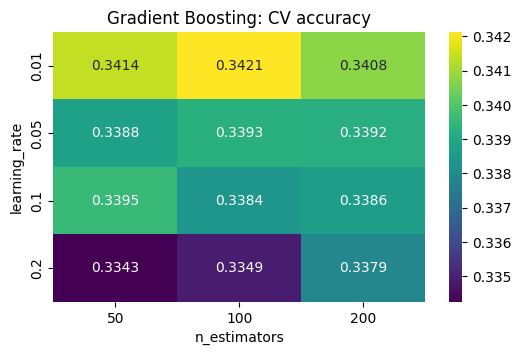


Random Forest (tuned) CV: 0.3427
Gradient Boosting (tuned) CV: 0.3421


In [9]:
gb_grid = {'learning_rate': [0.01, 0.05, 0.1, 0.2], 'n_estimators': [50, 100, 200]}
gb_gs = GridSearchCV(GradientBoostingClassifier(random_state=42),
                     gb_grid, cv=5, scoring='accuracy', n_jobs=-1)
gb_gs.fit(X_train, y_train)

print('GB best_params_:', gb_gs.best_params_)
print('GB best_score_ :', round(gb_gs.best_score_, 4))
n_gb = len(gb_grid['learning_rate']) * len(gb_grid['n_estimators'])
print(f'Trainings: {n_gb} combinations x 5 folds = {n_gb*5}')

res = pd.DataFrame(gb_gs.cv_results_)
heat = res.pivot(index='param_learning_rate', columns='param_n_estimators', values='mean_test_score').astype(float)
plt.figure(figsize=(6,3.5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis')
plt.title('Gradient Boosting: CV accuracy'); plt.ylabel('learning_rate'); plt.xlabel('n_estimators'); plt.show()

print('\nRandom Forest (tuned) CV:', round(rf_gs.best_score_, 4))
print('Gradient Boosting (tuned) CV:', round(gb_gs.best_score_, 4))

## Step 5: Check for overfitting
Train score vs test score for each tuned model. (Test set is used here only to measure the gap; the model choice is made from CV scores.)

In [10]:
tuned = {
    'KNN (K=%d)' % best_k:               make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
    'Decision Tree (depth=%s)' % best_depth: DecisionTreeClassifier(max_depth=best_depth, random_state=42),
    'Random Forest (tuned)':             rf_gs.best_estimator_,
    'Gradient Boosting (tuned)':         gb_gs.best_estimator_,
}
rows = []
for name, m in tuned.items():
    m.fit(X_train, y_train)
    tr, te = m.score(X_train, y_train), m.score(X_test, y_test)
    rows.append({'Model': name, 'Train score': tr, 'Test score': te, 'Gap': tr - te})
gap_table = pd.DataFrame(rows).round(4)
display(gap_table)

print('Most overfit  :', gap_table.loc[gap_table['Gap'].idxmax(), 'Model'])
print('Most stable   :', gap_table.loc[gap_table['Gap'].idxmin(), 'Model'], '(smallest gap)')

,Model,Train score,Test score,Gap
0,KNN (K=1),1.0000,0.3394,0.6606
1,Decision Tree (depth=2),0.3457,0.3337,0.0120
2,Random Forest (tuned),0.4369,0.3320,0.1049
3,Gradient Boosting (tuned),0.3762,0.3271,0.0491


Most overfit  : KNN (K=1)
Most stable   : Decision Tree (depth=2) (smallest gap)


## Step 6: Final test and decision
The final model is chosen from the **CV scores** (not the test set), then evaluated **once** on the test set.

Final model chosen by CV score: Random Forest (tuned) 0.3427

Test accuracy: 0.332


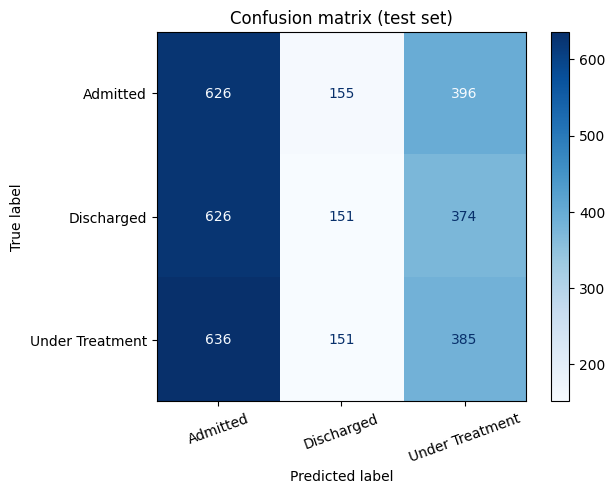

                 precision    recall  f1-score   support

       Admitted       0.33      0.53      0.41      1177
     Discharged       0.33      0.13      0.19      1151
Under Treatment       0.33      0.33      0.33      1172

       accuracy                           0.33      3500
      macro avg       0.33      0.33      0.31      3500
   weighted avg       0.33      0.33      0.31      3500



In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

cv_scores = {'Random Forest (tuned)': rf_gs.best_score_,
             'Gradient Boosting (tuned)': gb_gs.best_score_}
final_name  = max(cv_scores, key=cv_scores.get)
final_model = tuned[final_name]          # already fitted on the training set
print('Final model chosen by CV score:', final_name, round(cv_scores[final_name], 4))

y_pred = final_model.predict(X_test)      # <- single evaluation on the test set
print('\nTest accuracy:', round(accuracy_score(y_test, y_pred), 4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues', xticks_rotation=20)
plt.title('Confusion matrix (test set)'); plt.show()

print(classification_report(y_test, y_pred, target_names=le.classes_))

### Decision and explanation
**Final model: tuned Random Forest** (`max_depth=5`, `n_estimators=100`). Reasons:
1. Highest CV accuracy on the training data (0.3427 vs 0.3421 for tuned Gradient Boosting), so the choice does not use the test set. Note this is a tiny difference (within the CV std), so the two are effectively tied.
2. Ensembles average many trees, so they are more stable than KNN (K=1 memorises, train 1.00 vs test 0.34).
3. Its gap (0.105) is larger than Decision Tree (0.012) and Gradient Boosting (0.049). If I wanted the safest model for generalisation, the shallow Gradient Boosting or Decision Tree would be the more conservative choice.

**Overfitting:** KNN (K=1) overfits the most (gap 0.66). The Decision Tree with depth 2 is the most stable (gap 0.012).

**Gradient Boosting vs Random Forest (bonus):** best GB was `learning_rate=0.01`, `n_estimators=100` (CV 0.3421). A small learning rate means GB learns slowly and almost does not fit anything, which is a sign there is no real signal in the data.

**Honest observation:** every model scores about 0.33 (chance level for 3 balanced classes) and the test accuracy of the final model is 0.332. The features (age, gender, department, diagnosis, treatment, bill amount, dates) contain almost no information about `status`; the data looks randomly generated. In a real project I would report this, check the data source, or choose a more meaningful target (for example `diagnosis` or `department`) and add real clinical features. In the classification report the model predicts *Admitted* too often (recall 0.53) and *Discharged* rarely (recall 0.13); this is a bias, not real skill.

**Precision or recall?** For a hospital problem, **recall matters more**. Missing a patient who still needs care (for example predicting *Discharged* when the patient is really *Admitted* / *Under Treatment*) is a bigger risk than a false alarm, which only costs some extra checking. I would keep precision acceptable so staff are not flooded with false alerts, but recall comes first.